# MISR to AT3D Preprocessing of the observations (BRF and geometry)

**Warning:** It is important that cells be run in order and without duplication. Certain transformations modify variables in place and applying the transformation twice will yield unexpected behavior.

After MISR data has been reformatted into the custom xarray format (i.e. `MISR_preprocessA.ipynb`), the data are processed in this notebook. The steps that take place here are:

1. Azimuth coordinate transformation
2. SOM x and y coordinate transformation
3. Merge position and view geometry ray-by-ray
4. Perform wind correction
5. Project imagery to the top of a radiative transfer grid
6. Convert $BRF$ to $I^*$

In [1]:
# conda env 'at3d_pure_k9'
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import at3d

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

from src.utils.util import save_sensor_dict
import src.CoordinateTransform as ct

In [2]:
orbit = 105254
path = 117
imagery = xr.load_dataset(PROJECT_ROOT / 'data' / 'interim' / f'MISR_RAD_O{orbit:06d}_P{path:03d}_R00275_X17950487_18003012_Y0193187_0245712.nc')
gmp = xr.load_dataset(PROJECT_ROOT / 'data' / 'interim' / f'MISR_GEO_O{orbit:06d}_P{path:03d}_R17600_X17959150_17994350_Y0201850_0237050.nc')

## 1. Azimuth angle coordiante transform

Convert from azimuth relative to local north going clockwise to azimuth angles relative to local east going counter-clockwise.

$\phi_E = (90 - \phi_N) \mod 360$

Such that $\phi_N$ is the azimuthal angle (degrees) relative to local north going clockwise, and $\phi_E$ is the new azimuthal angle (degrees) relative to local east going counter-clockwise.

In [3]:
for var in gmp.data_vars:
    if('Azimuth' in var):
        gmp[var] = (90 - gmp[var]) % 360
        gmp[var].attrs['description'] = 'Azimuth relative to local East going counter-clockwise'

## 2. SOM x and y coordinate transform

In [4]:
origin = gmp.isel(som_x=1, som_y=1)
transform = ct.CoordinateTransform(
    origin.som_x.data,
    origin.som_y.data,
    origin.gamma.data,
    17600,
    17600
)
print(transform)

X, Y = np.meshgrid(imagery.som_x, imagery.som_y, indexing='ij')
Xp, Yp = transform.SOM2AT3D(X, Y)

imagery['x'] = (['som_x', 'som_y'], Xp)
imagery['y'] = (['som_x', 'som_y'], Yp)
imagery['z'] = (['som_x', 'som_y'], np.zeros_like(X))

Domain center som x: 17976750.0
Domain center som y: 219450.0
AT3D domain length x: 17600
AT3D domain length y: 17600
gamma: 1.655084388740932 radians


In [5]:
# ## Create AT3D coordinates
# origin = gmp.isel(som_x=1, som_y=1)
# X, Y = np.meshgrid(imagery.som_x, imagery.som_y, indexing='ij')
# ## 1. Translation setting origin to domain center
# Xt = X - origin.som_x.data
# Yt = Y - origin.som_y.data
# # 2. Rotation about the origin orienting with north
# Xtr = Xt * np.cos(origin.gamma.data) + Yt * np.sin(origin.gamma.data)
# Ytr = -Xt * np.sin(origin.gamma.data) + Yt * np.cos(origin.gamma.data)
# ## 3. Translation setting corner of domain
# Xtrt = Xtr + 8800
# Ytrt = Ytr + 8800

# imagery['x'] = (['som_x', 'som_y'], Xtrt)
# imagery['y'] = (['som_x', 'som_y'], Ytrt)
# imagery['z'] = (['som_x', 'som_y'], np.zeros_like(X))

## 3. Merge position (x, y, z) and viewing geometry

In [11]:
phi = np.array([origin[f'{c.lower().capitalize()}Azimuth'].data for c in imagery.camera.data])
mu = np.array([origin[f'{c.lower().capitalize()}Zenith'].data for c in imagery.camera.data])

In [12]:
print(imagery.camera.data)
print(phi)
print(mu)

['DF' 'CF' 'BF' 'AF' 'AN' 'AA' 'BA' 'CA' 'DA']
[ 72.019944    70.45855356  67.62234824  60.37507497 347.75077605
 269.34135341 261.85587018 259.02491631 257.55655947]
[70.42228051 60.33261609 46.15332394 27.1948554   7.21664647 26.57757211
 45.67785273 60.06890652 70.35949442]


In [6]:
tmp_shape = (imagery.sizes['camera'], imagery.sizes['som_x'], imagery.sizes['som_y'])
imagery['x'] = (['camera', 'som_x', 'som_y'], np.broadcast_to(imagery.x.data, tmp_shape))
imagery['y'] = (['camera', 'som_x', 'som_y'], np.broadcast_to(imagery.y.data, tmp_shape))
imagery['z'] = (['camera', 'som_x', 'som_y'], np.broadcast_to(imagery.z.data, tmp_shape))

phi = np.array([origin[f'{c.lower().capitalize()}Azimuth'].data for c in imagery.camera.data])
phi = np.radians(phi)
imagery['phi'] = (['camera', 'som_x', 'som_y'], np.broadcast_to(phi[:, None, None], tmp_shape))

mu = np.array([origin[f'{c.lower().capitalize()}Zenith'].data for c in imagery.camera.data])
mu = np.cos(np.radians(mu))
imagery['mu'] = (['camera', 'som_x', 'som_y'], np.broadcast_to(mu[:, None, None], tmp_shape))

## 4. Wind correction

In [7]:
u = 0.856 # m/s
v = 1.232 # m/s

imagery['deltat'] = (['camera'], np.array([-204, -144, -91, -45, 0, 45, 91, 144, 204]))

imagery['x'] = imagery.x - u*imagery.deltat
imagery['y'] = imagery.y - v*imagery.deltat

## 5. Create AT3D sensor objects

- Transform each ray to top of radiative transfer domain
- Convert $R$ to $I^*$

$I^* = \frac{R\mu_0}{\pi}$

Where $R$ is the MISR BRF and $\mu_0$ is the cosine of the solar zenith angle.

In [8]:
def register_to_height(x, y, z, mu, phi, h):
    """
    Transform x, y coordinates to be registered at height h.
    
    Parameters:
    -----------
    x, y, z : array-like
        Original coordinates
    mu : array-like
        Cosine of zenith angle
    phi : array-like
        Azimuthal angle in radians
    h : float
        Target height for registration
        
    Returns:
    --------
    x_new, y_new : arrays
        Transformed coordinates at height h
    """
    # Calculate the distance to travel along the viewing direction
    # to reach height h
    dz = h - z
    
    # sin(zenith) = sqrt(1 - mu^2)
    sin_zenith = np.sqrt(1 - mu**2)
    
    # Displacement in x and y directions
    dx = (dz / mu) * sin_zenith * np.cos(phi)
    dy = (dz / mu) * sin_zenith * np.sin(phi)
    
    # New coordinates
    x_new = x + dx
    y_new = y + dy
    z_new = h * np.ones_like(z)
    
    return x_new, y_new, z_new

In [ ]:
h = 1400
wavelength = 0.67

obs = at3d.containers.SensorsDict()
for c in imagery.camera.data:
    img_tmp = imagery.sel(camera=c)
    x = np.ravel(img_tmp.x.data)
    y = np.ravel(img_tmp.y.data)
    z = np.ravel(img_tmp.z.data)
    mu = np.ravel(img_tmp.mu.data)
    phi = np.ravel(img_tmp.phi.data)
    x, y, z = register_to_height(x, y, z, mu, phi, h)
    mu0 = np.cos(np.radians(origin.SolarZenith.data))
    I = (np.ravel(img_tmp.brf.data) * mu0) / np.pi
    sensor = at3d.sensor.make_sensor_dataset(
        x/1000,
        y/1000,
        z/1000,
        mu,
        phi,
        'I',
        wavelength,
        fill_ray_variables = True
    )
    sensor['I'] = (['nrays'], I)
    sensor['I'].attrs['description'] = 'I = (BRF_MISR * mu0) / pi = I / F_0'
    sensor['brf'] = (['nrays'], np.ravel(img_tmp.brf.data))
    sensor['brf'].attrs['description'] = 'MISR BRF'
    sensor['mu0'] = mu0
    sensor['mu0'].attrs['long_name'] = 'cosine of the solar zenith angle'
    sensor['SAA'] = origin.SolarAzimuth.data
    sensor['SAA'].attrs['description'] = origin.SolarAzimuth.description
    sensor['SAA'].attrs['units'] = 'degrees'
    sensor.attrs['name'] = c
    sensor.attrs['wind_correction_u'] = u
    sensor.attrs['wind_correction_v'] = v
    obs.add_sensor('MISR', sensor)

outfilename = f'AT3D_OBS_O{orbit:06d}_{imagery.regionID}_H{int(h):d}_U{str(u).replace(".","p")}_V{str(v).replace(".","p")}.nc'
save_sensor_dict(PROJECT_ROOT / 'data' / 'interim' / outfilename, obs)

/data/gdi/b/johntl3/LundstromPub2025/src/utils/util.py:41: RuntimeWarning: file_name '/data/gdi/b/johntl3/LundstromPub2025/data/interim/AT3D_OBS_O105254_P117_R00275_X17950487_18003012_Y0193187_0245712_H1400_U0p856_V1p232.nc' already exists, your file is now at '/data/gdi/b/johntl3/LundstromPub2025/data/interim/AT3D_OBS_O105254_P117_R00275_X17950487_18003012_Y0193187_0245712_H1400_U0p856_V1p232_2.nc'
  warnings.warn("file_name '{}' already exists, your file is now at '{}'".format(


Saved sensors to: /data/gdi/b/johntl3/LundstromPub2025/data/interim/AT3D_OBS_O105254_P117_R00275_X17950487_18003012_Y0193187_0245712_H1400_U0p856_V1p232_2.nc


## Plot

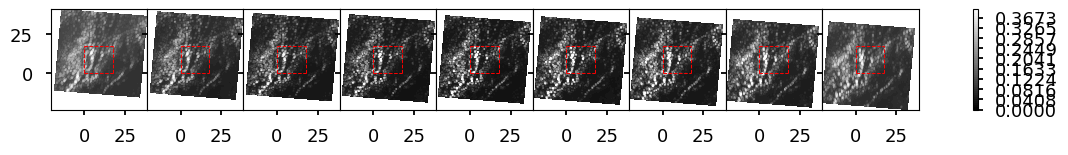

In [10]:
plt.style.use('seaborn-v0_8-talk')
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}

f, ax = plt.subplots(1, 9, figsize=(14, 1.3), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.0, hspace=0.0)

for i, cam in enumerate(obs['MISR']['sensor_list']):
    c = ax[i].tricontourf(cam.ray_x.data, cam.ray_y.data, cam.brf.data, **plot_kwargs)
plt.colorbar(c, ax=ax[:])

box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
ticks = [0.0, 17.6]
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    # a.set_xticks(ticks)
    # a.set_xticklabels(ticks, rotation=45)
    # a.set_yticks(ticks)
    # a.set_xlim([0,17.6])
    # a.set_ylim([0,17.6])